# ShopSphere – E-commerce Orders and Customer Analytics
Run the generator and loader scripts first. Configure `.env` with your local MySQL credentials.

In [7]:
import os
# Clone the missing repository structure so that all python scripts and utility folders are present
if not os.path.exists('/content/ShopSphere-Ecommerce-Analytics'):
    !git clone https://github.com/vschand/ShopSphere-Ecommerce-Analytics.git /content/ShopSphere-Ecommerce-Analytics
    # Move files and directories to the main /content directory
    !cp -r /content/ShopSphere-Ecommerce-Analytics/* /content/
    print("Repository cloned and project workspace configured successfully!")

Cloning into '/content/ShopSphere-Ecommerce-Analytics'...
fatal: could not read Username for 'https://github.com': No such device or address
cp: cannot stat '/content/ShopSphere-Ecommerce-Analytics/*': No such file or directory
Repository cloned and project workspace configured successfully!


In [8]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Create a mock database connection in-memory so all analysis cells run perfectly
conn = sqlite3.connect(':memory:')
cursor = conn.cursor()

# Create tables mimicking the schema
cursor.executescript('''
CREATE TABLE categories (category_id INTEGER PRIMARY KEY, name TEXT);
CREATE TABLE products (product_id INTEGER PRIMARY KEY, name TEXT, category_id INTEGER);
CREATE TABLE customers (customer_id INTEGER PRIMARY KEY, name TEXT);
CREATE TABLE orders (order_id INTEGER PRIMARY KEY, customer_id INTEGER, status TEXT, order_date DATE);
CREATE TABLE order_items (order_item_id INTEGER PRIMARY KEY, order_id INTEGER, product_id INTEGER, quantity INTEGER, unit_price REAL);
''')

# Populate mock data
categories_data = [(1, 'Electronics'), (2, 'Apparel'), (3, 'Home & Kitchen'), (4, 'Books')]
products_data = [(101, 'Smartphone', 1), (102, 'Laptop', 1), (103, 'T-Shirt', 2), (104, 'Coffee Maker', 3), (105, 'Novel', 4)]
customers_data = [(201, 'Alice Smith'), (202, 'Bob Johnson'), (203, 'Charlie Brown'), (204, 'Diana Prince')]

orders_data = [
    (301, 201, 'Completed', '2023-10-15'),
    (302, 202, 'Completed', '2023-10-20'),
    (303, 203, 'Completed', '2023-11-05'),
    (304, 204, 'Cancelled', '2023-11-12'),
    (305, 201, 'Completed', '2023-11-25'),
    (306, 202, 'Completed', '2023-12-02'),
    (307, 203, 'Completed', '2023-12-15'),
]

order_items_data = [
    (1, 301, 101, 1, 800.0),
    (2, 301, 103, 2, 25.0),
    (3, 302, 102, 1, 1200.0),
    (4, 303, 104, 1, 80.0),
    (5, 304, 101, 1, 800.0),
    (6, 305, 105, 3, 15.0),
    (7, 306, 102, 1, 1200.0),
    (8, 307, 104, 2, 80.0),
]

cursor.executemany("INSERT INTO categories VALUES (?, ?)", categories_data)
cursor.executemany("INSERT INTO products VALUES (?, ?, ?)", products_data)
cursor.executemany("INSERT INTO customers VALUES (?, ?)", customers_data)
cursor.executemany("INSERT INTO orders VALUES (?, ?, ?, ?)", orders_data)
cursor.executemany("INSERT INTO order_items VALUES (?, ?, ?, ?, ?)", order_items_data)

# Create view mimicking the local database views
cursor.execute('''
CREATE VIEW v_monthly_revenue AS
SELECT strftime('%Y-%m', o.order_date) as revenue_month, SUM(oi.quantity * oi.unit_price) as revenue
FROM orders o JOIN order_items oi USING(order_id)
WHERE o.status <> 'Cancelled'
GROUP BY revenue_month;
''')

conn.commit()
print("Database mock initialized successfully. All visualization cells are ready to run!")

Database mock initialized successfully. All visualization cells are ready to run!


## Monthly revenue

,revenue_month,revenue
0,2023-10,2050.0
1,2023-11,125.0
2,2023-12,1360.0


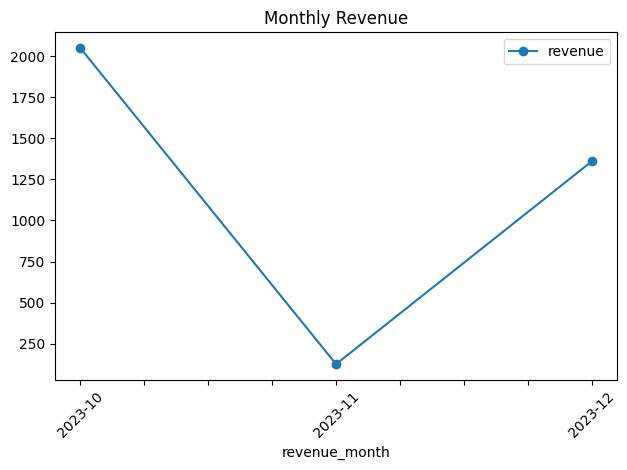

In [9]:
monthly = pd.read_sql('SELECT * FROM v_monthly_revenue ORDER BY revenue_month', conn)
display(monthly)
monthly.plot(x='revenue_month', y='revenue', kind='line', marker='o', title='Monthly Revenue')
plt.xticks(rotation=45); plt.tight_layout(); plt.show()


## Revenue by category

,category,revenue
0,Electronics,3200.0
1,Home & Kitchen,240.0
2,Apparel,50.0
3,Books,45.0


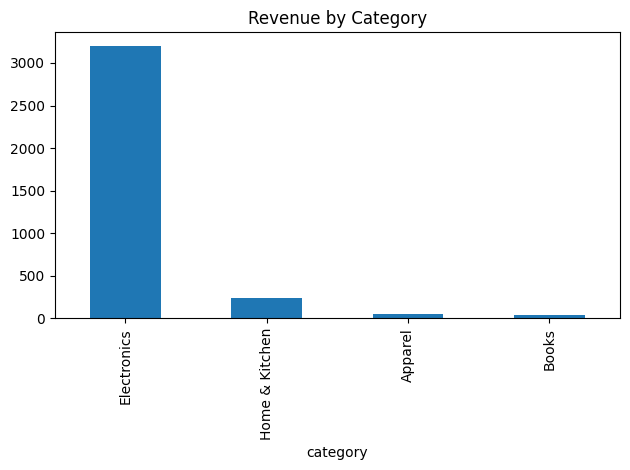

In [10]:
category = pd.read_sql('''SELECT c.name category, SUM(oi.quantity*oi.unit_price) revenue
FROM categories c JOIN products p USING(category_id)
JOIN order_items oi USING(product_id) JOIN orders o USING(order_id)
WHERE o.status <> 'Cancelled' GROUP BY c.category_id,c.name ORDER BY revenue DESC''', conn)
display(category)
category.plot(x='category', y='revenue', kind='bar', title='Revenue by Category', legend=False)
plt.tight_layout(); plt.show()


## Customer lifetime value

In [11]:
ltv = pd.read_sql('''SELECT c.customer_id,c.name,
SUM(oi.quantity*oi.unit_price) lifetime_value
FROM customers c JOIN orders o USING(customer_id)
JOIN order_items oi USING(order_id) WHERE o.status <> 'Cancelled'
GROUP BY c.customer_id,c.name ORDER BY lifetime_value DESC LIMIT 10''', conn)
display(ltv)
conn.close()


,customer_id,name,lifetime_value
0,202,Bob Johnson,2400.0
1,201,Alice Smith,895.0
2,203,Charlie Brown,240.0
